# 19장 모델 설계 레시피와 모델 기반 데이터 분석 (실습)

17장의 T-미로 에이전트를 「피험자」로 삼는다. 피험자마다 먹이 선호 C 와 정책 정밀도 γ 가 다르다. 그들이 남긴 선택만 보고 C 와 γ 를 거꾸로 추정한다(모델 반전).

1. T-미로 모델 (17장에서 가져옴)
2. 피험자 한 명의 선택
3. 우도 지형
4. 매개변수 복원
5. 시행 수와 복원
6. 모델 비교
7. 계산 표현형 — 두 집단의 γ
8. 실패 조건 — 틀린 모델로 적합하면

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정
from scipy import stats

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

EPS = 1e-16
def ln(x):
    return np.log(x + EPS)

def softmax(v):
    e = np.exp(v - v.max())
    return e / e.sum()

print("시드", SEED)

시드 1234


## 1. T-미로 모델

17장과 같다. 위치 넷(출발점, 단서 바위, 왼쪽 굴, 오른쪽 굴) × 맥락 둘, 관측 세 갈래(위치, 먹이, 단서).

In [2]:
L, K = 4, 2
S = L * K
def idx(l, c):
    return l * K + c

def build(p_food=0.98):
    A_loc = np.zeros((L, S)); A_food = np.zeros((3, S)); A_cue = np.zeros((3, S))
    for l in range(L):
        for c in range(K):
            s = idx(l, c); A_loc[l, s] = 1
            if l in (2, 3):
                good = (l - 2) == c
                A_food[1, s] = p_food if good else 1 - p_food; A_food[2, s] = 1 - A_food[1, s]
            else:
                A_food[0, s] = 1
            if l == 1:
                A_cue[1 + c, s] = 1
            else:
                A_cue[0, s] = 1
    B = np.zeros((L, S, S))
    for u in range(L):
        for l in range(L):
            for c in range(K):
                B[u][idx(l if l in (2, 3) else u, c), idx(l, c)] = 1
    return [A_loc, A_food, A_cue], B

def Cvec(food, poison=-6.0):
    return [np.zeros(L), np.array([0.0, food, poison]), np.zeros(3)]

def H(A):
    return -np.sum(A * ln(A), axis=0)

def step_G(s, As, Cs, w_epi=1.0):
    G = 0.0
    for A, Cm in zip(As, Cs):
        o = A @ s
        G += -w_epi * (-o @ ln(o) - s @ H(A)) - o @ ln(softmax(Cm))
    return G

def G_policy(s, pi, As, B, Cs, w_epi=1.0):
    G = 0.0
    for u in pi:
        s = B[u] @ s; G += step_G(s, As, Cs, w_epi)
    return G

def update(prior, obs, As):
    q = prior.copy()
    for A, o in zip(As, obs):
        q = q * A[o]
    return q / q.sum()

As, B = build()
print("상태", S, "개, 관측 갈래", len(As), "개, 행동", L, "개")

상태 8 개, 관측 갈래 3 개, 행동 4 개


## 2. 피험자 한 명의 선택

실험자는 시행마다 먹이가 왼쪽에 있을 확률 p 를 0.5, 0.6, 0.7, 0.8, 0.9 가운데 하나로 알려 준다. 시행은 40 번이다. 피험자는 17장의 표준 계획으로 행동을 고른다. 같은 믿음·지평·C 에서의 G 는 캐시에 담아 재사용한다(γ 는 G 를 바꾸지 않는다).

In [3]:
P_SET = [0.5, 0.6, 0.7, 0.8, 0.9]
_cache = {}

def Gvec(q, h, food, w_epi):
    key = (tuple(np.round(q, 6)), h, round(food, 6), w_epi)
    if key not in _cache:
        pols = list(itertools.product(range(L), repeat=h))
        G = np.array([G_policy(q, pi, As, B, Cvec(food), w_epi) for pi in pols])
        _cache[key] = (G, np.array([pi[0] for pi in pols]))
    return _cache[key]

def action_probs(q, h, food, gamma, w_epi=1.0):
    G, first = Gvec(q, h, food, w_epi)
    qu = np.bincount(first, weights=softmax(-gamma * G), minlength=L)
    return qu / qu.sum()

def run_subject(food, gamma, n, rng, w_epi=1.0):
    """시행마다 (믿음, 남은 걸음, 고른 행동) 두 개를 기록한다"""
    data = []
    for k in range(n):
        p = P_SET[k % len(P_SET)]
        ctx = 0 if rng.random() < p else 1
        q = np.zeros(S); q[idx(0, 0)] = p; q[idx(0, 1)] = 1 - p
        s_true = idx(0, ctx); trial = []
        for t in range(2):
            u = rng.choice(L, p=action_probs(q, 2 - t, food, gamma, w_epi))
            s_true = np.argmax(B[u][:, s_true])
            obs = [rng.choice(A.shape[0], p=A[:, s_true]) for A in As]
            trial.append((q.copy(), 2 - t, u, p))
            q = update(B[u] @ q, obs, As)
        data.append(trial)
    return data

def cue_rate(data):
    rows = {}
    for trial in data:
        q, h, u, p = trial[0]
        rows.setdefault(p, []).append(u == 1)
    return {p: np.mean(v) for p, v in sorted(rows.items())}

rng = np.random.default_rng(SEED)
for food, gamma in [(3.0, 8.0), (6.0, 8.0), (3.0, 0.7)]:
    d = run_subject(food, gamma, 40, rng)
    print(f"C(먹이) = {food}, γ = {gamma}:  p 별 단서 먼저 비율",
          {p: float(round(r, 2)) for p, r in cue_rate(d).items()})

C(먹이) = 3.0, γ = 8.0:  p 별 단서 먼저 비율 {0.5: 1.0, 0.6: 1.0, 0.7: 0.12, 0.8: 0.0, 0.9: 0.0}
C(먹이) = 6.0, γ = 8.0:  p 별 단서 먼저 비율 {0.5: 0.62, 0.6: 0.0, 0.7: 0.0, 0.8: 0.0, 0.9: 0.0}
C(먹이) = 3.0, γ = 0.7:  p 별 단서 먼저 비율 {0.5: 0.38, 0.6: 0.62, 0.7: 0.38, 0.8: 0.38, 0.9: 0.12}


## 3. 우도 지형

피험자의 선택 기록이 주어지면 (C, γ) 의 로그 우도는 매 결정에서 그 피험자가 실제로 고른 행동의 확률의 로그 합이다. C 15 개 × γ 15 개 격자에서 계산한다.

참값 C = 4.5, γ = 2.0   추정 C = 4.00, γ = 2.00   최대 로그 우도 -57.4


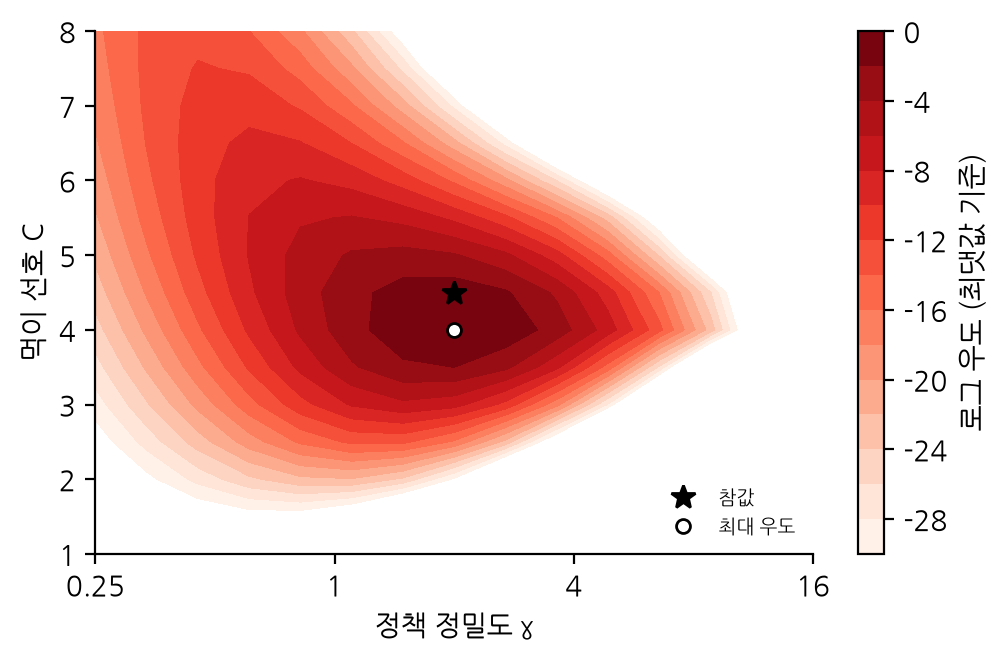

In [4]:
CF = np.linspace(1, 8, 15)
GA = np.exp(np.linspace(np.log(0.25), np.log(16), 15))

def loglik_grid(data, w_epi=1.0):
    LL = np.zeros((len(CF), len(GA)))
    for i, food in enumerate(CF):
        for j, g in enumerate(GA):
            LL[i, j] = sum(np.log(action_probs(q, h, food, g, w_epi)[u] + 1e-12)
                           for trial in data for q, h, u, p in trial)
    return LL

def fit(data, w_epi=1.0):
    LL = loglik_grid(data, w_epi)
    i, j = np.unravel_index(LL.argmax(), LL.shape)
    return CF[i], GA[j], LL.max(), LL

rng = np.random.default_rng(3)
true_food, true_gamma = 4.5, 2.0
d = run_subject(true_food, true_gamma, 40, rng)
f_hat, g_hat, ll, LL = fit(d)
print(f"참값 C = {true_food}, γ = {true_gamma}   추정 C = {f_hat:.2f}, γ = {g_hat:.2f}   최대 로그 우도 {ll:.1f}")

fig, ax = plt.subplots(figsize=(5.2, 3.4))
im = ax.contourf(np.log2(GA), CF, LL - LL.max(), levels=np.linspace(-30, 0, 16), cmap="Reds")
ax.plot(np.log2(true_gamma), true_food, "k*", ms=9, label="참값")
ax.plot(np.log2(g_hat), f_hat, "wo", ms=5, mec="k", label="최대 우도")
ax.set_xticks(np.log2([0.25, 1, 4, 16])); ax.set_xticklabels(["0.25", "1", "4", "16"])
ax.set_xlabel("정책 정밀도 γ"); ax.set_ylabel("먹이 선호 C")
fig.colorbar(im, ax=ax, label="로그 우도 (최댓값 기준)")
ax.legend(fontsize=7, frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

## 4. 매개변수 복원

피험자 30 명을 만든다. C 는 2~7 에서, γ 는 0.5~8 에서(로그 균등) 뽑는다. 각자 40 시행을 하고, 그 기록으로 추정한 값을 참값과 견준다.

40 시행: C 상관 0.902,  log γ 상관 0.917


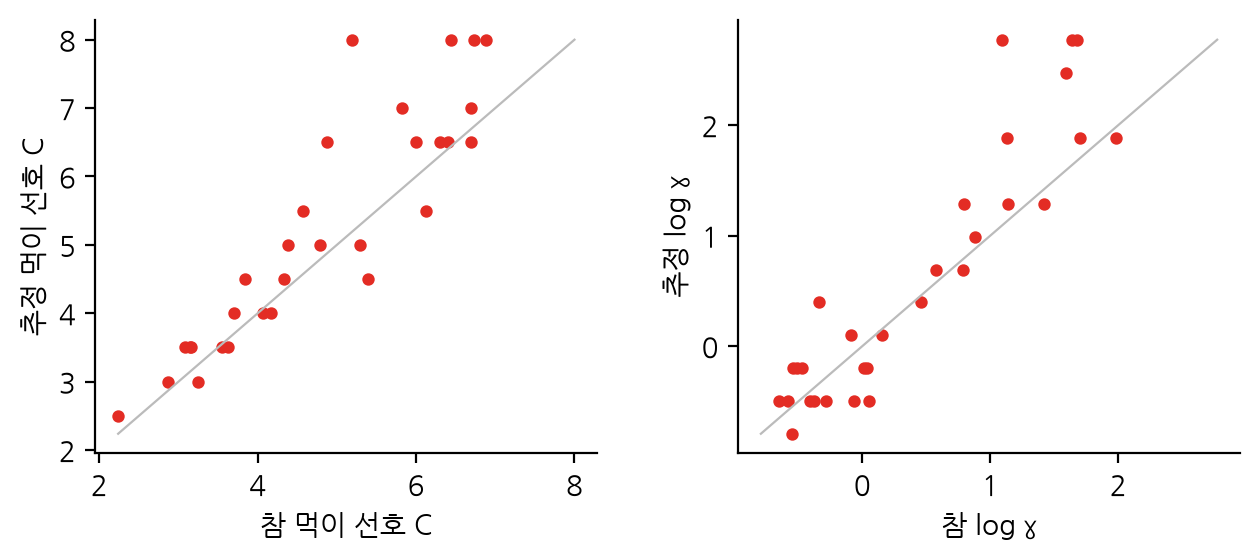

In [5]:
def recovery(n_trials, n_sub=30, seed=0):
    rng = np.random.default_rng(seed); T, E = [], []
    for s in range(n_sub):
        food = rng.uniform(2, 7); g = np.exp(rng.uniform(np.log(0.5), np.log(8)))
        f_hat, g_hat, _, _ = fit(run_subject(food, g, n_trials, rng))
        T.append((food, np.log(g))); E.append((f_hat, np.log(g_hat)))
    return np.array(T), np.array(E)

T40, E40 = recovery(40)
r_c = np.corrcoef(T40[:, 0], E40[:, 0])[0, 1]; r_g = np.corrcoef(T40[:, 1], E40[:, 1])[0, 1]
print(f"40 시행: C 상관 {r_c:.3f},  log γ 상관 {r_g:.3f}")
fig, ax = plt.subplots(1, 2, figsize=(6.4, 2.9))
for a, k, lab in [(ax[0], 0, "먹이 선호 C"), (ax[1], 1, "log γ")]:
    a.scatter(T40[:, k], E40[:, k], s=12, color="#E32C24")
    lo, hi = min(T40[:, k].min(), E40[:, k].min()), max(T40[:, k].max(), E40[:, k].max())
    a.plot([lo, hi], [lo, hi], color="#BBBBBB", lw=0.8)
    a.set_xlabel(f"참 {lab}"); a.set_ylabel(f"추정 {lab}")
plt.tight_layout(); plt.show()

## 5. 시행 수와 복원

In [6]:
for n in [10, 40, 160]:
    T, E = recovery(n)
    print(f"{n:4d} 시행: C 상관 {np.corrcoef(T[:, 0], E[:, 0])[0, 1]:.3f},  "
          f"log γ 상관 {np.corrcoef(T[:, 1], E[:, 1])[0, 1]:.3f}")

  10 시행: C 상관 0.915,  log γ 상관 0.666


  40 시행: C 상관 0.902,  log γ 상관 0.917


 160 시행: C 상관 0.989,  log γ 상관 0.961


## 6. 모델 비교

정보 이득을 쓰는 피험자(완전한 G)와 쓰지 않는 피험자(실용적 가치만) 20 명씩을 만든다. 두 모델을 모두 적합하고 최대 로그 우도가 큰 쪽을 고른다. 두 모델의 매개변수 수(2)가 같으므로 BIC 비교와 같다.

In [7]:
rng = np.random.default_rng(5)
conf = np.zeros((2, 2), int)
for row, gen in enumerate([1.0, 0.0]):
    for s in range(20):
        food = rng.uniform(2, 7); g = np.exp(rng.uniform(np.log(1), np.log(8)))
        d = run_subject(food, g, 40, rng, w_epi=gen)
        l_full = fit(d, 1.0)[2]; l_prag = fit(d, 0.0)[2]
        conf[row, 0 if l_full > l_prag else 1] += 1
print("            고른 모델:  완전한 G   실용적 가치만")
print(f"참 모델 완전한 G     {conf[0, 0]:8d} {conf[0, 1]:12d}")
print(f"참 모델 실용적 가치만 {conf[1, 0]:8d} {conf[1, 1]:12d}")

            고른 모델:  완전한 G   실용적 가치만
참 모델 완전한 G           17            3
참 모델 실용적 가치만        0           20


## 7. 계산 표현형 — 두 집단의 γ

집단 A 는 γ 가 4 근처, 집단 B 는 1 근처인 피험자 15 명씩이다(C 는 3~5). 추정한 log γ 로 두 집단을 견준다.

In [8]:
rng = np.random.default_rng(9)
groups = {}
for name, gm in [("A", 4.0), ("B", 1.0)]:
    est = []
    for s in range(15):
        food = rng.uniform(3, 5); g = gm * np.exp(rng.normal(0, 0.3))
        est.append(np.log(fit(run_subject(food, g, 40, rng))[1]))
    groups[name] = np.array(est)
t, pval = stats.ttest_ind(groups["A"], groups["B"])
for k, v in groups.items():
    print(f"집단 {k}: 추정 γ 의 기하 평균 {np.exp(v.mean()):.2f}")
print(f"t = {t:.2f},  p = {pval:.1e}")

집단 A: 추정 γ 의 기하 평균 4.88
집단 B: 추정 γ 의 기하 평균 1.15
t = 9.81,  p = 1.5e-10


## 8. 실패 조건 — 틀린 모델로 적합하면

정보 이득을 쓰지 않는 피험자 15 명의 기록에 완전한 G 모델을 적합한다.

In [9]:
rng = np.random.default_rng(11)
rows = []
for s in range(15):
    food = rng.uniform(2, 7); g = np.exp(rng.uniform(np.log(1), np.log(8)))
    f_hat, g_hat, _, _ = fit(run_subject(food, g, 40, rng, w_epi=0.0), 1.0)
    rows.append((food, g, f_hat, g_hat))
rows = np.array(rows)
print(f"C:  참 평균 {rows[:, 0].mean():.2f},  추정 평균 {rows[:, 2].mean():.2f}")
print(f"γ:  참 기하 평균 {np.exp(np.log(rows[:, 1]).mean()):.2f},  추정 기하 평균 {np.exp(np.log(rows[:, 3]).mean()):.2f}")

C:  참 평균 4.52,  추정 평균 4.47
γ:  참 기하 평균 3.38,  추정 기하 평균 1.78
